In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder, MinMaxScaler, StandardScaler, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_curve, roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.multiclass import OneVsRestClassifier
import joblib

In [2]:
DATASET_PATH = '../Data/Raw/raw_dataset.csv'
TEST_DATASET_PATH = '../Data/Processed/test_dataset.csv'

def load_dataset(path: str):
    if not os.path.exists(path): return None
    return pd.read_csv(path)
    
dataset = load_dataset(DATASET_PATH)
# dataset.drop(columns='Student_ID', inplace=True)
dataset

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low


In [3]:
def fix_non_real_screen_times(dataset: pd.DataFrame, drop=False):
    mask = dataset['Social_Media_Hours'] > dataset['Screen_Time_Hours']

    if drop:
        indices = dataset[mask].index
        dataset = dataset.drop(indices)
    else:
        tmp = dataset['Screen_Time_Hours'].iloc[mask]
        dataset.loc[mask, 'Screen_Time_Hours'] = dataset['Social_Media_Hours'].iloc[mask]
        dataset.loc[mask, 'Social_Media_Hours'] = tmp

    mask = dataset['Social_Media_Hours'] > dataset['Screen_Time_Hours']
    print(f'Non Logic Screen Time Counts : {mask.sum()}')


fix_non_real_screen_times(dataset)

Non Logic Screen Time Counts : 0


In [4]:
def drop_non_impacting_columns(dataset: pd.DataFrame, columns=[]):
    return dataset.drop(columns=columns)

dataset = drop_non_impacting_columns(dataset, ['Age', 'Gender', 'Student_ID'])

In [5]:
mask = ((~dataset.isna()) & (~dataset.isnull())).all(axis=1)
print(f'{((~mask).mean() * 100):.2f}% of the data contain null values')

19.70% of the data contain null values


In [6]:
dataset

,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low


In [31]:
X, y = dataset.iloc[:, :-1], dataset.iloc[:, -1:]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=50, stratify=y)
y_train, y_test = np.ravel(y_train), np.ravel(y_test)

In [32]:
# def get_ages_studied_years_dist(dataset: pd.DataFrame, norm_age = 23):

#     min_age = dataset['Age'].min()
#     years = norm_age - min_age
#     fig, axes = plt.subplots(years, figsize=(10, 12))

#     for id, year in enumerate(range(min_age, norm_age)):

#         sns.barplot(data=dataset['Year_of_Study'][dataset['Age'] == year].value_counts(), ax=axes[id])
#         axes[id].set_title(f'{year} Studied Years Dist')
        
#     plt.tight_layout()

# get_ages_studied_years_dist(train_dataset)

In [33]:
def process_non_binary_gender(dataset: pd.DataFrame, drop=True):
    if drop:
        indices = dataset[dataset['Gender'] == 'Non-binary'].index
        dataset = dataset.drop(indices)
    print(f'{(dataset['Gender'] == 'Non-binary').sum()} of non binary gender exists in data')

# process_non_binary_gender(train_dataset)

In [34]:
X_train.head()

,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History
1232,3,4.7,22.6,1.76,7.0,8.2,High,NaN,7.6,87.3,No,Good,Yes
449,2,6.4,15.5,2.54,6.7,10.6,Low,NaN,7.1,87.8,Yes,Poor,No
1055,3,5.4,17.1,2.36,7.5,9.8,High,6.7,9.4,89.1,No,Good,No
3,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes
1003,2,7.8,21.5,2.64,6.6,8.7,High,7.0,8.5,79.1,No,Average,Yes


In [ ]:
encoded_cols = X_test.select_dtypes(include='str').columns

norm_cols = np.array(['Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours'])
stand_cols = np.array(['Year_of_Study', 'Financial_Stress', 'Family_Support', 'Attendance_Rate'])

# Categorical pipeline
encoder = Pipeline(steps=[
    ('Imputing', SimpleImputer(strategy='most_frequent')),
    ('Str_Enc', OrdinalEncoder(
        categories=[
            ['Low', 'Moderate', 'High'],
            ['No', 'Yes'],
            ['Poor', 'Average', 'Good'],
            ['No', 'Yes']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=np.nan
    ))
])

# Numerical pipelines
norm_pipeline = Pipeline(steps=[
    ('Imputer', IterativeImputer()),
    ('Norm', MinMaxScaler())
])

stand_pipeline = Pipeline(steps=[
    ('Imputer', IterativeImputer()),
    ('Stand', StandardScaler())
])

# Combined preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('Str_Enc', encoder, encoded_cols),
    ('Norm', norm_pipeline, norm_cols),
    ('Stand', stand_pipeline, stand_cols)
], verbose_feature_names_out=False, remainder='passthrough').set_output(transform='pandas')

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

		=== Train LogisticRegression Model ===

		=== LogisticRegression Score : 0.76 ===

		LogisticRegression Classification Repport: {'High': {'precision': 0.8082191780821918, 'recall': 0.8676470588235294, 'f1-score': 0.8368794326241135, 'support': 68.0}, 'Low': {'precision': 0.803030303030303, 'recall': 0.803030303030303, 'f1-score': 0.803030303030303, 'support': 66.0}, 'Medium': {'precision': 0.6557377049180327, 'recall': 0.6060606060606061, 'f1-score': 0.6299212598425197, 'support': 66.0}, 'accuracy': 0.76, 'macro avg': {'precision': 0.7556623953435091, 'recall': 0.7589126559714795, 'f1-score': 0.7566103318323121, 'support': 200.0}, 'weighted avg': {'precision': 0.7561879631708961, 'recall': 0.76, 'f1-score': 0.75741302284023, 'support': 200.0}}
		=== Train RandomForestClassifier Model ===

		=== RandomForestClassifier Score : 0.69 ===

		RandomForestClassifier Classification Repport: {'High': {'precision': 0.717948717948718, 'recall': 0.8235294117647058, 'f1-score': 0.7671232876712328

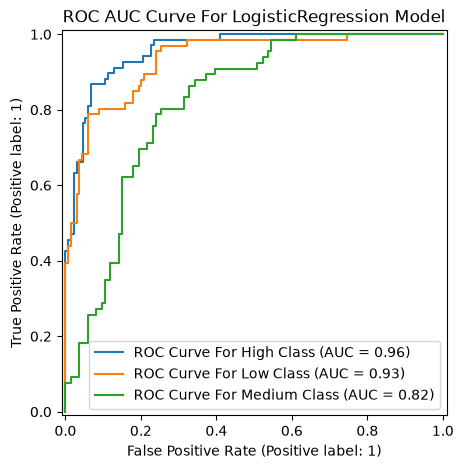

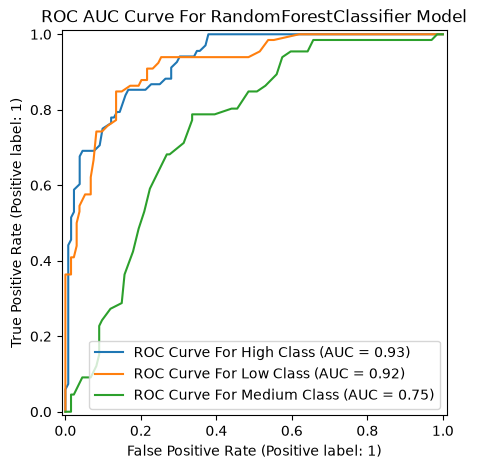

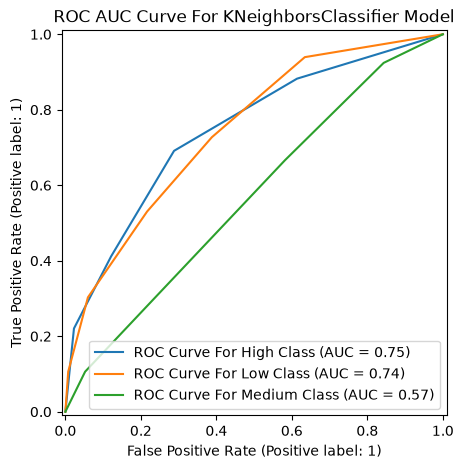

In [15]:
models = {
    'LogisticRegression': {
        'model': LogisticRegression(max_iter=1000),
        'grid_params': [
                        {
                            'solver': [
                                'lbfgs',
                                'newton-cg',
                                'newton-cholesky',
                                'sag'
                            ],
                            'C': [0.01, 0.1, 1, 10, 100]
                        },

                        {
                            'solver': ['saga'],
                            'C': [0.01, 0.1, 1, 10, 100]
                        },

                        {
                            'solver': ['saga'],
                            'C': [0.01, 0.1, 1, 10, 100],
                            'l1_ratio': [0.25, 0.5, 0.75]
                        }
                    ]
    },
    'RandomForestClassifier': {
        'model': RandomForestClassifier(),
        'grid_params': {
                        'n_estimators': [100, 200],
                        'criterion': ['gini', 'entropy'],
                        'max_depth': [None, 10, 20],
                        'min_samples_split': [2, 5],
                        'min_samples_leaf': [1, 2, 4],
                        'max_features': ['sqrt', 'log2'],
                        'class_weight': [None, 'balanced']
                    }
    },
    'KNeighborsClassifier': {
        'model': KNeighborsClassifier(),
        'grid_params': {
                        'n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
                        'weights': ['uniform', 'distance'],
                        'metric': ['minkowski'],
                        'p': [1, 2]
                    }
    }
}

FIG_COLORS = np.array(["aqua", "darkorange", "cornflowerblue"])

for k, v in models.items():
    
    print(f'\t\t=== Train {k} Model ===\n')
    model = v['model']

    model.fit(X_train, y_train)
    score = model.score(X_test, y_test)
    print(f'\t\t=== {k} Score : {score} ===\n')

    prediction_probas = model.predict_proba(X_test)
    predictions = model.classes_[np.argmax(prediction_probas,  axis=1)]

    class_report = classification_report(y_test, predictions, output_dict=True)
    print(f'\t\t{k} Classification Repport: {class_report}')

    classes = model.classes_
    y_test_binz = label_binarize(y_test, classes=classes)

    fpr = [0] * 3
    tpr = [0] * 3
    thresholds = [0] * 3
    auc = [0] * 3

    for i, class_label in enumerate(model.classes_):
        fpr[i], tpr[i], thresholds[i] = roc_curve(y_true=y_test_binz[:, i], y_score=prediction_probas[:, i])
        auc[i] = roc_auc_score(y_true=y_test_binz[:, i], y_score=prediction_probas[:, i])

    fig, ax = plt.subplots(figsize=(5, 5))

    for class_id in range(3):
        RocCurveDisplay.from_predictions(
            y_test_binz[:, class_id],
            prediction_probas[:, class_id],
            name=f'ROC Curve For {classes[class_id]} Class',
            ax=ax
        )
        ax.set_title(f'ROC AUC Curve For {k} Model')

    v['classification_rapport'] = class_report
    v['score'] = score
    v['auc_roc_fig'] = fig


In [16]:
for model_name, model_data in models.items():

    model_grid = GridSearchCV(model_data['model'], model_data['grid_params'], n_jobs=-1)
    model_grid.fit(X_train, y_train)

    print(f'Best Params For {model_name} : {model_grid.best_params_}')

    score = model_grid.score(X_test, y_test)
    print(f'Score Of {model_name} : {score}')

    model_data['grid_instance'] = model_grid


Best Params For LogisticRegression : {'C': 1, 'l1_ratio': 0.75, 'solver': 'saga'}
Score Of LogisticRegression : 0.745
Best Params For RandomForestClassifier : {'class_weight': None, 'criterion': 'entropy', 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Score Of RandomForestClassifier : 0.715
Best Params For KNeighborsClassifier : {'metric': 'minkowski', 'n_neighbors': 15, 'p': 1, 'weights': 'distance'}
Score Of KNeighborsClassifier : 0.55


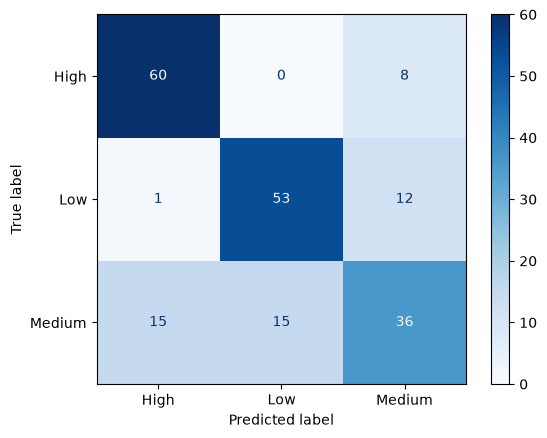

,High,Low,Medium,accuracy,macro avg,weighted avg
precision,0.789474,0.779412,0.642857,0.745,0.737248,0.737770
recall,0.882353,0.803030,0.545455,0.745,0.743613,0.745000
f1-score,0.833333,0.791045,0.590164,0.745,0.738181,0.739132
support,68.000000,66.000000,66.000000,0.745,200.000000,200.000000


In [18]:
best_model = models['LogisticRegression']['grid_instance'].best_estimator_
y_pred = best_model.predict(X_test)

class_report = pd.DataFrame(classification_report(y_true=y_test, y_pred=y_pred, output_dict=True))

ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_pred, labels=np.unique(y_test), cmap='Blues')
plt.show()
display(class_report)

In [45]:
preprocessor = ColumnTransformer(transformers=[
    ('Str_Enc', encoder, encoded_cols),
    ('Norm', norm_pipeline, norm_cols),
    ('Stand', stand_pipeline, stand_cols)
], verbose_feature_names_out=False, remainder='passthrough').set_output(transform='pandas')

full_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', best_model)
])

joblib.dump(full_pipeline, '../Models/Full_Pipeline.pkl')

['../Models/Full_Pipeline.pkl']

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Year_of_Study','Sleep_Hours','Study_Hours_Per_Week',...,'Part_Time_Job', 'Diet_Quality','Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Str_Enc', ...), ('Norm', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns ar